# Comparing BFS and A* Search

# Code

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import numpy as np
import maze_helper as mh

#f = open("small_maze.txt", "r")
#f = open("medium_maze.txt", "r")
#f = open("large_maze.txt", "r")    # this has only one solution!
#f = open("open_maze.txt", "r")
#f = open("empty_maze.txt", "r")
#f = open("empty_maze_2.txt", "r")
#f = open("loops_maze.txt", "r")
f = open("L_maze.txt", "r")

maze_str = f.read()
maze = mh.parse_maze(maze_str)

In [2]:
# tree_search_solution.py has my actual implementation (not published)
import tree_search_solution as ts


# order in which we add new states to the frontier
ts.set_order("NESW")
#ts.set_order(random=True)

## BFS

Breadth-first search is an _optimal_ algorithm. BFS is an _uninformed search algorithm and has no idea where the goal is. It expands the search in concentric circles around the start till it hits the goal.

In [3]:
%time result = ts.best_first_search(maze, strategy = "BFS", debug = False, vis = False, animation = True)

ts.animate_maze(result)

CPU times: total: 0 ns
Wall time: 946 μs


Note that BFS explores almost the whole maze. BFS keeps the whole tree (notes are represented by gray squares) in memory. This is a problem for many AI problems with large state spaces. 

## A* Search - Euclidean Heuristic

A* Search is an _informed_ search algorithms. It gets information about where the goal is using the heuristic function. The value of the heuristic function tends to decrease the closer we get to the goal. It is optimal if A* is an admissible heuristic.

In [4]:
# set heuristic for my A* search implementation
#ts.heuristic = ts.manhattan
ts.heuristic = ts.euclidean

%time result = ts.best_first_search(maze, strategy = "A*", debug = False, vis = False, animation = True)
ts.animate_maze(result)

CPU times: total: 0 ns
Wall time: 611 μs


## A* Search - Manhattan Heuristic

In [5]:
# set heuristic for my A* search implementation
ts.heuristic = ts.manhattan
#ts.heuristic = ts.euclidean

%time result = ts.best_first_search(maze, strategy = "A*", debug = False, vis = False, animation = True)
ts.animate_maze(result)

CPU times: user 7.4 ms, sys: 0 ns, total: 7.4 ms
Wall time: 7.19 ms
Path length: 16
Reached squares: 66
Action sequence: ['E', 'E', 'E', 'E', 'S', 'E', 'E', 'E', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N']


## Comparison

* BFS and A* search are both optimal and find the shortest possible path.
* BFS explores 142 states and needs to store a tree of that size, while A* explores significantly less.
* The effectiveness of A* depends on how good the heuristic is. Manhatten distance is a very good heuristic for this problem.
* For some AI problems, the smaller tree that A* creates may still be too large for the available memory. Here other methods weighted A* search or, iterative deepening search may need to be used. 

# Bài 5 

,Maze,Thuật toán,Path cost,Nút mở rộng,Max depth,Max frontier,Thời gian (ms)
0,mê cung đang chọn (maze),BFS,16,152,16,17,0.79
1,mê cung đang chọn (maze),A* Euclidean,16,63,16,27,0.44
2,mê cung đang chọn (maze),A* Manhattan,16,41,16,29,0.31
3,medium,BFS,68,270,68,9,1.07
4,medium,A* Euclidean,68,225,68,8,1.12
5,medium,A* Manhattan,68,218,68,8,1.21
6,large,BFS,210,622,210,8,2.47
7,large,A* Euclidean,210,555,210,10,2.75
8,large,A* Manhattan,210,543,210,12,2.63
9,open,BFS,54,683,54,25,3.06


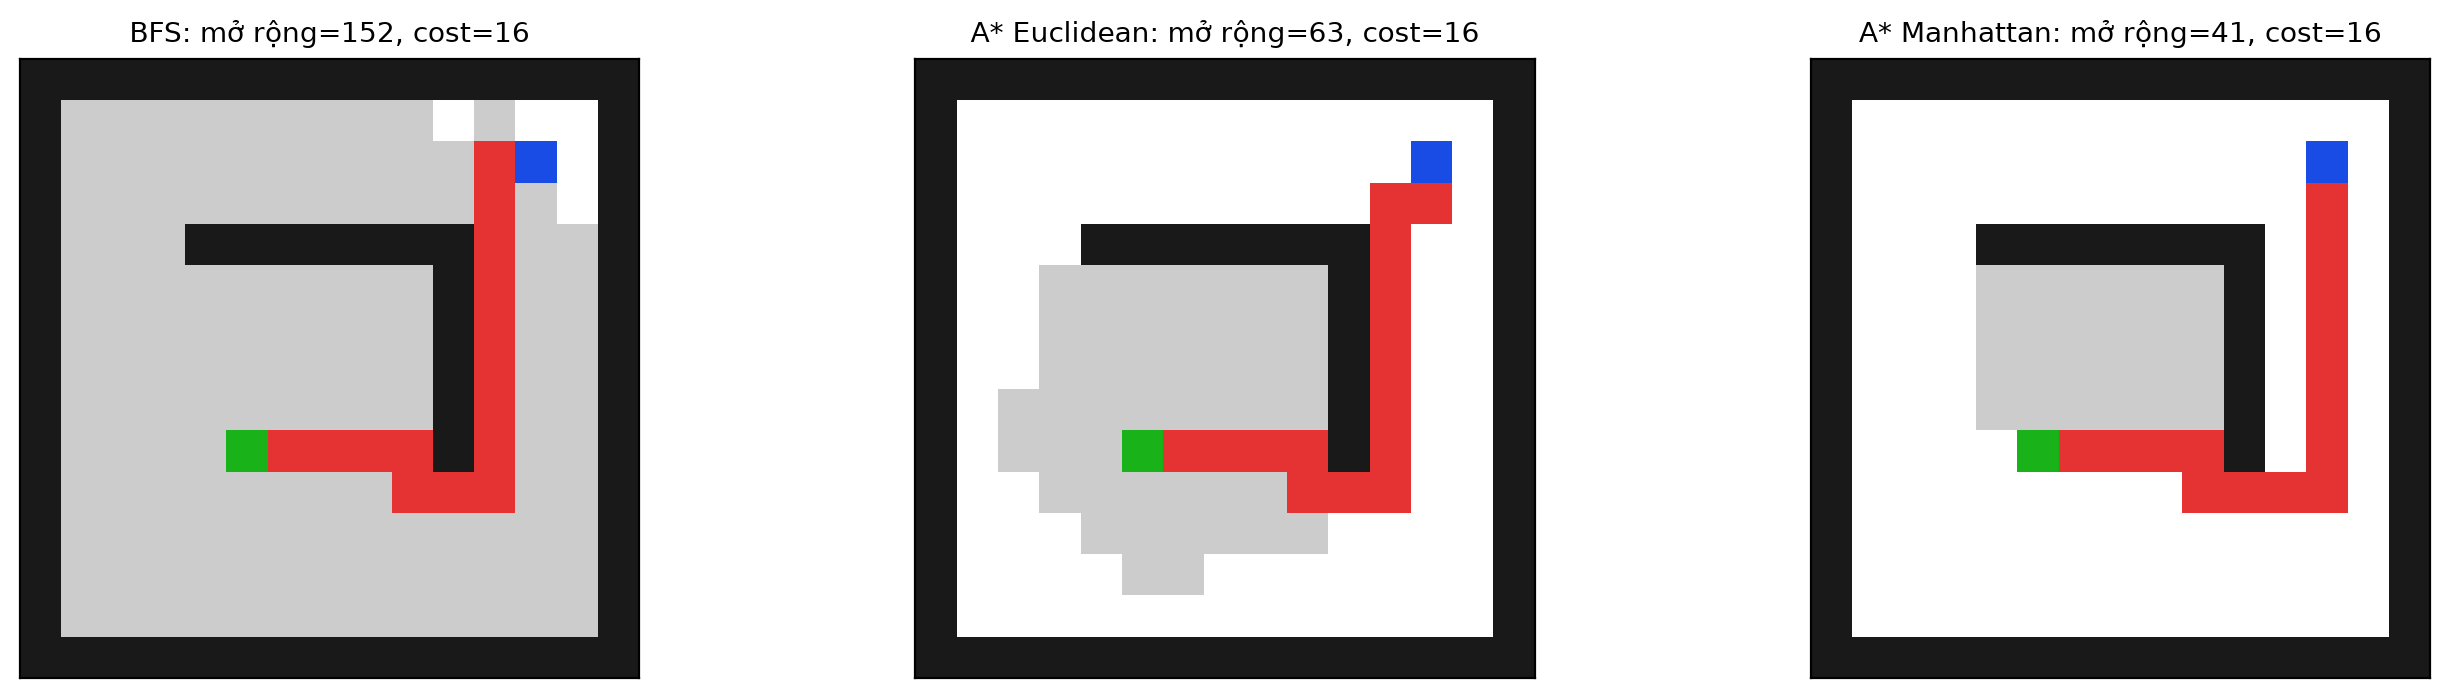

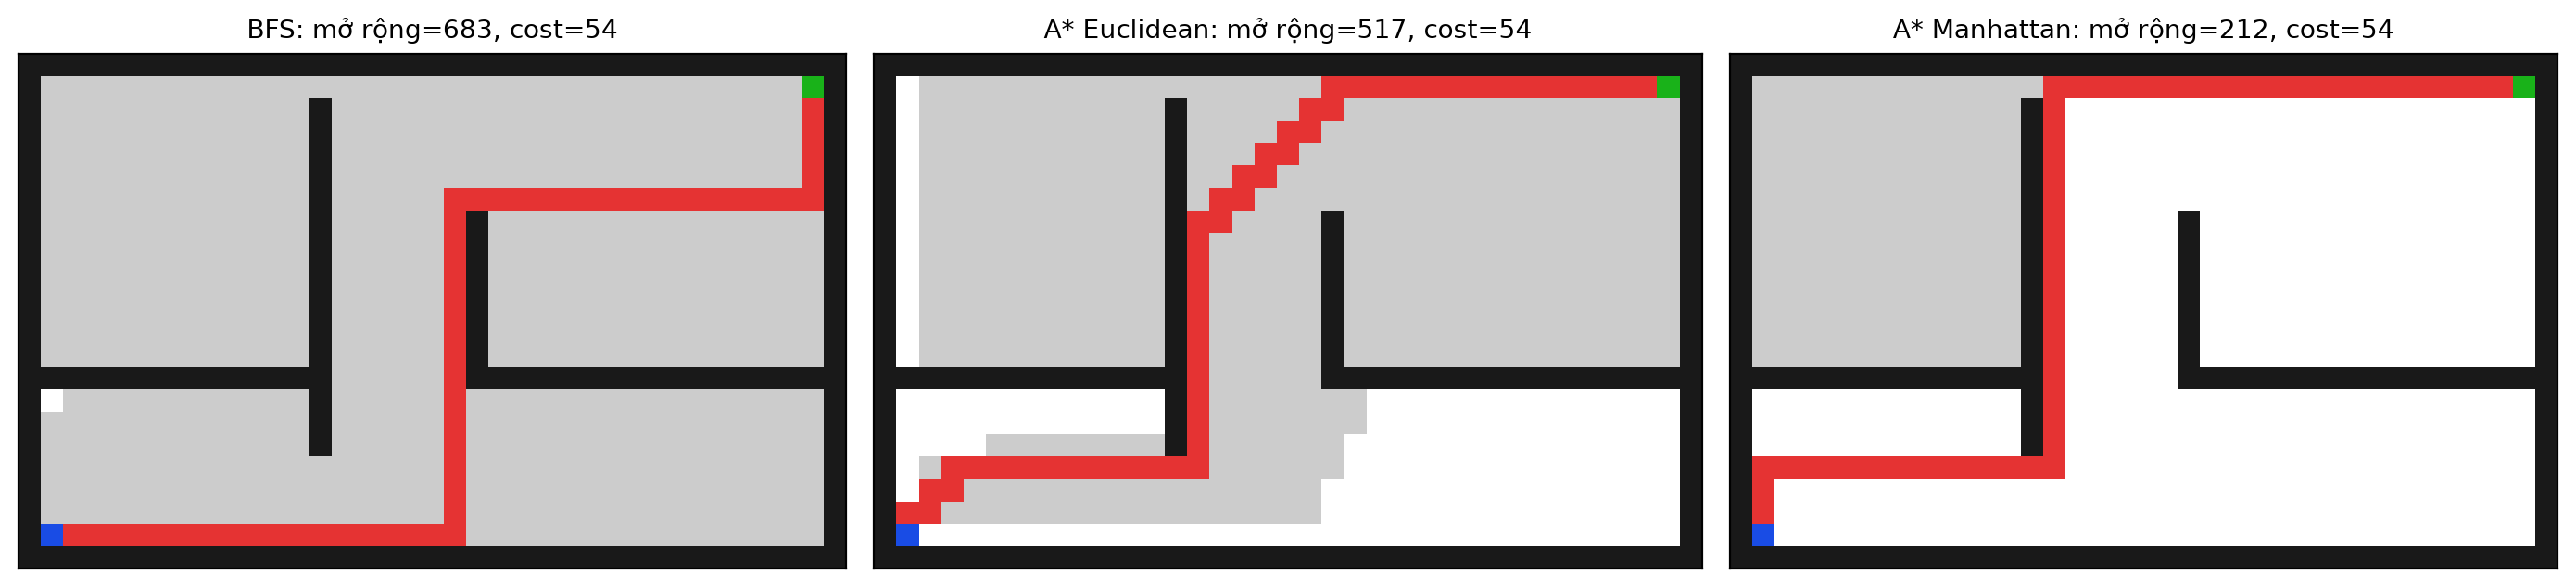

-> mê cung đang chọn (maze): BFS mở rộng 152 nút, A* Manhattan 41 nút, A* Euclidean 63 nút (path cost đều = 16).
-> medium: BFS mở rộng 270 nút, A* Manhattan 218 nút, A* Euclidean 225 nút (path cost đều = 68).
-> large: BFS mở rộng 622 nút, A* Manhattan 543 nút, A* Euclidean 555 nút (path cost đều = 210).
-> open: BFS mở rộng 683 nút, A* Manhattan 212 nút, A* Euclidean 517 nút (path cost đều = 54).


In [5]:
# ===== Bài 5: so sánh trực tiếp BFS với A* (Euclidean / Manhattan) =====
import pandas as pd
import matplotlib.pyplot as plt

def load_maze(name):
    return mh.parse_maze(open(f"{name}_maze.txt").read())

def compare(mz):
    runs = {}
    ts.set_order("NESW"); runs["BFS"] = ts.best_first_search(mz, strategy="BFS", debug=False, vis=False)
    for hname, h in [("Euclidean", ts.euclidean), ("Manhattan", ts.manhattan)]:
        ts.heuristic = h
        ts.set_order("NESW"); runs[f"A* {hname}"] = ts.best_first_search(mz, strategy="A*", debug=False, vis=False)
    ts.heuristic = ts.manhattan
    return runs

cases = {"mê cung đang chọn (maze)": maze, "medium": load_maze("medium"), "large": load_maze("large"), "open": load_maze("open")}
rows, allruns = [], {}
for cname, mz in cases.items():
    allruns[cname] = compare(mz)
    for aname, r in allruns[cname].items():
        rows.append({"Maze": cname, "Thuật toán": aname, "Path cost": r["cost"], "Nút mở rộng": r["expanded"],
                     "Max depth": r["max_depth"], "Max frontier": r["max_frontier"], "Thời gian (ms)": round(r["time"] * 1000, 2)})
table = pd.DataFrame(rows)
table.to_csv("ket_qua_bfs_vs_astar.csv", index=False)
display(table)

# Hai hình minh họa đường đi và vùng đã khảo sát (xám) cho báo cáo
for cname, fname in [("mê cung đang chọn (maze)", "hinh_bai5_bfs_vs_astar_maze.png"), ("open", "hinh_bai5_bfs_vs_astar_open.png")]:
    fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
    for ax, (aname, r) in zip(axs, allruns[cname].items()):
        ts.show_path(cases[cname], r, ax=ax, title=f"{aname}: mở rộng={r['expanded']}, cost={r['cost']}")
    plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()

for cname, rr in allruns.items():
    print(f"-> {cname}: BFS mở rộng {rr['BFS']['expanded']} nút, A* Manhattan {rr['A* Manhattan']['expanded']} nút, "
          f"A* Euclidean {rr['A* Euclidean']['expanded']} nút (path cost đều = {rr['BFS']['cost']}).")

# Nhận xét BFS và A\* (Bài 5)

Kết quả đo được (path cost đều bằng nhau giữa BFS và A\* trên mỗi mê cung):

| Mê cung | Path cost | BFS | A\* Euclidean | A\* Manhattan | Max frontier (BFS / Euc / Man) |
|---|---|---|---|---|---|
| `L_maze` (đang chọn) | 16 | 152 | 63 | **41** | 17 / 27 / 29 |
| `medium` | 68 | 270 | 225 | **218** | 9 / 8 / 8 |
| `large` | 210 | 622 | 555 | **543** | 8 / 10 / 12 |
| `open` | 54 | 683 | 517 | **212** | 25 / 51 / 185 |

* **Cả hai đều tối ưu:** BFS và A\* (Euclidean lẫn Manhattan) luôn cho cùng path cost (16, 68, 210, 54), vì cả hai heuristic đều admissible. Điều này khớp với kết luận trong cell *Comparison* gốc.
* **A\* mở rộng ít nút hơn BFS, mức giảm phụ thuộc cấu trúc mê cung:** `L_maze` giảm ≈ 73 % (41 so với 152), `open` giảm ≈ 69 % (212 so với 683), còn `medium` và `large` chỉ giảm ≈ 19 % và ≈ 13 %, nhiều khả năng vì hai mê cung này có ít chỗ trống để heuristic cắt bớt nút (`large` còn chỉ có một lời giải). Trong cell A\* Manhattan, dòng *Reached squares: 66* là số ô đã được sinh ra (reached) còn 41 là số ô thực sự được mở rộng. Con số 142 trong cell *Comparison* gốc là của lần chạy của tác giả; bài làm này đo được 152 (khác nhau nhẹ do cách đếm), kết luận không đổi.
* **Manhattan tốt hơn Euclidean** trên lưới 4 hướng: Manhattan bằng đúng chi phí thật khi không có tường, còn Euclidean luôn nhỏ hơn hoặc bằng nên đánh giá thấp và A\* phải mở rộng nhiều nút hơn (`L_maze` 63 so với 41; `open` 517 so với 212). Chênh lệch lớn ở `open` và `L_maze`; ở `medium` và `large` hai heuristic gần như nhau (225/218 và 555/543).
* **Bộ nhớ: A\* ít nút hơn nhưng frontier có thể lớn hơn.** Ghi chú gốc nói BFS giữ cả cây trong bộ nhớ, đúng với tổng số nút mở rộng (683 so với 212 ở `open`). Nhưng nếu đo bằng đỉnh frontier thì A\* lại lớn hơn BFS ở `L_maze` (29 so với 17), `large` (12 so với 8) và đặc biệt `open` (185 so với 25), vì ở mê cung trống nhiều nút có cùng `f = g + h` cùng nằm chờ trong frontier.
* **Thời gian:** ít nút hơn chưa chắc nhanh hơn do A\* tốn thêm chi phí hàng đợi ưu tiên và tính heuristic: A\* Manhattan nhanh hơn rõ ở `open` (1,40 ms so với 3,06 ms) và `L_maze` (0,31 ms so với 0,79 ms) nhưng không nhanh hơn ở `medium` (1,21 ms so với 1,07 ms) và `large` (2,63 ms so với 2,47 ms).
* **Kết luận:** hiệu quả của A\* phụ thuộc chất lượng heuristic và cấu trúc bài toán: lợi nhiều ở `open` và `L_maze`, ít ở `medium` và `large`. Khi cây của A\* vẫn quá lớn so với bộ nhớ thì cần các phương pháp khác như Weighted A\* hay IDS (đánh đổi: mất tối ưu hoặc tốn thời gian, xem notebook `02_Maze_Example.ipynb`).